# P2 — Fintech Transaction Fraud Scoring & High-Value Customer Segmentation
**Deliverables:** Decision Tree vs Random Forest comparison; fraud threshold analysis; K-means clusters. Dataset is synthetic starter data.

In [18]:
!pip -q install scikit-learn matplotlib seaborn joblib

In [19]:
from pathlib import Path
import os
DATA_DIR = Path("/kaggle/input/datasets/babblu123/real-world-ml-genai-kaggle-complete/real_world_ml_genai_lab/datasets")
if not DATA_DIR.exists():
    DATA_DIR = Path("../datasets")
if not DATA_DIR.exists():
    DATA_DIR = Path("datasets")
print("Dataset directory:", DATA_DIR.resolve())

import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
df=pd.read_csv(DATA_DIR/"p2_fintech_transactions.csv")
df.head()

Dataset directory: /kaggle/input/datasets/babblu123/real-world-ml-genai-kaggle-complete/real_world_ml_genai_lab/datasets


,transaction_id,customer_id,amount,location_delta_km,velocity_1h,customer_age,device_status,channel,account_tenure_days,is_fraud
0,TX0000000,10900,50.71,21.52,1,23,new,WEB,3402,0
1,TX0000001,11029,497.94,4.69,2,54,known,WEB,617,0
2,TX0000002,10510,418.54,32.89,0,29,new,POS,2821,0
3,TX0000003,11507,533.04,32.57,1,22,new,POS,1693,0
4,TX0000004,10021,734.28,11.73,4,68,known,WEB,3285,0


(8000, 10)


transaction_id         0
customer_id            0
amount                 0
location_delta_km      0
velocity_1h            0
customer_age           0
device_status          0
channel                0
account_tenure_days    0
is_fraud               0
dtype: int64

is_fraud
0    0.962125
1    0.037875
Name: share, dtype: float64

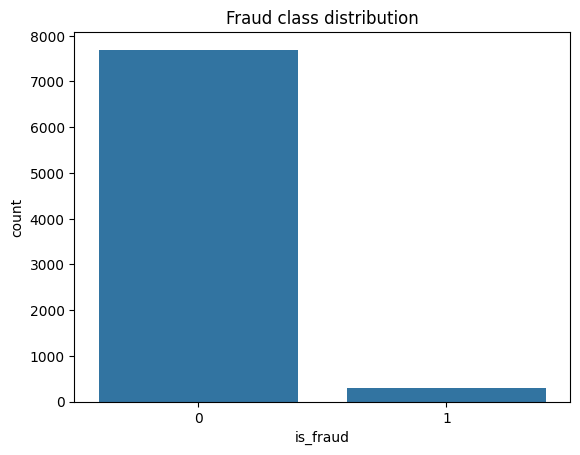

In [20]:
print(df.shape); display(df.isna().sum()); display(df["is_fraud"].value_counts(normalize=True).rename("share"))
sns.countplot(data=df,x="is_fraud"); plt.title("Fraud class distribution"); plt.show()

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
target="is_fraud"
features=["amount","location_delta_km","velocity_1h","customer_age","device_status","channel","account_tenure_days"]
X=df[features]; y=df[target]
X_train,X_temp,y_train,y_temp=train_test_split(X,y,test_size=.3,random_state=42,stratify=y)
X_val,X_test,y_val,y_test=train_test_split(X_temp,y_temp,test_size=.5,random_state=42,stratify=y_temp)
num=["amount","location_delta_km","velocity_1h","customer_age","account_tenure_days"]; cat=["device_status","channel"]
prep=ColumnTransformer([("num",Pipeline([("impute",SimpleImputer(strategy="median")),("scale",StandardScaler())]),num),("cat",Pipeline([("impute",SimpleImputer(strategy="most_frequent")),("oh",OneHotEncoder(handle_unknown="ignore"))]),cat)])
models={"Decision Tree":DecisionTreeClassifier(max_depth=8,class_weight="balanced",random_state=42),
        "Random Forest":RandomForestClassifier(n_estimators=250,min_samples_leaf=3,class_weight="balanced_subsample",n_jobs=-1,random_state=42)}
fitted={}
for name,model in models.items():
    pipe=Pipeline([("prep",prep),("model",model)]); pipe.fit(X_train,y_train); fitted[name]=pipe
    pv=pipe.predict_proba(X_val)[:,1]
    print(name,"validation ROC-AUC",round(roc_auc_score(y_val,pv),4),"PR-AUC",round(average_precision_score(y_val,pv),4))

Decision Tree validation ROC-AUC 0.4992 PR-AUC 0.0601
Random Forest validation ROC-AUC 0.7314 PR-AUC 0.1284


In [22]:
rows=[]
for name,pipe in fitted.items():
    p=pipe.predict_proba(X_test)[:,1]; pred=(p>=.5).astype(int)
    rows.append({"model":name,"ROC_AUC":roc_auc_score(y_test,p),"PR_AUC":average_precision_score(y_test,p),"precision":precision_score(y_test,pred,zero_division=0),"recall":recall_score(y_test,pred,zero_division=0),"F1":f1_score(y_test,pred,zero_division=0)})
comparison=pd.DataFrame(rows).sort_values("PR_AUC",ascending=False)
display(comparison)

,model,ROC_AUC,PR_AUC,precision,recall,F1
1,Random Forest,0.778624,0.217360,0.571429,0.088889,0.153846
0,Decision Tree,0.508629,0.080646,0.048507,0.288889,0.083067


Chosen model: Random Forest threshold: 0.0583
              precision    recall  f1-score   support

           0       0.99      0.54      0.70      1155
           1       0.07      0.84      0.12        45

    accuracy                           0.55      1200
   macro avg       0.53      0.69      0.41      1200
weighted avg       0.95      0.55      0.68      1200



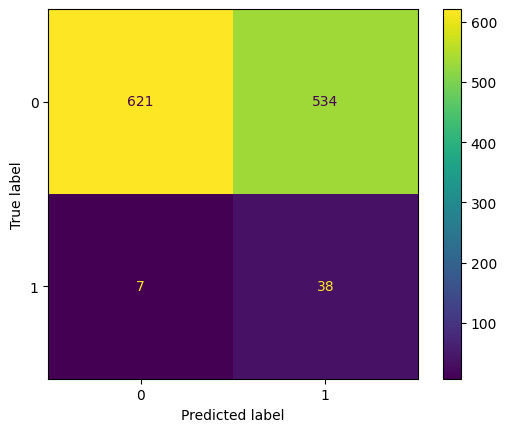

In [23]:
# Select alert threshold on validation data for a target recall; evaluate only once on test.
best_name=comparison.iloc[0]["model"]; best=fitted[best_name]
val_probs=best.predict_proba(X_val)[:,1]
from sklearn.metrics import precision_recall_curve
precision,recall,thresholds=precision_recall_curve(y_val,val_probs)
target_recall=.80
valid=np.where(recall[:-1]>=target_recall)[0]
threshold=float(thresholds[valid[-1]]) if len(valid) else .5
test_probs=best.predict_proba(X_test)[:,1]; test_pred=(test_probs>=threshold).astype(int)
print("Chosen model:",best_name,"threshold:",round(threshold,4))
print(classification_report(y_test,test_pred,zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred); plt.show()

In [24]:
# Customer-level aggregation for segmentation (exclude target label from clustering).
cust=df.groupby("customer_id").agg(txn_count=("transaction_id","count"),total_amount=("amount","sum"),avg_amount=("amount","mean"),avg_velocity=("velocity_1h","mean"),unique_channels=("channel","nunique"),fraud_count=("is_fraud","sum")).reset_index()
cluster_features=["txn_count","total_amount","avg_amount","avg_velocity","unique_channels"]
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
Z=StandardScaler().fit_transform(cust[cluster_features])
scores=[]
for k in range(2,7):
    km=KMeans(n_clusters=k,random_state=42,n_init=10).fit(Z)
    scores.append({"k":k,"inertia":km.inertia_,"silhouette":silhouette_score(Z,km.labels_)})
score_df=pd.DataFrame(scores); display(score_df)

,k,inertia,silhouette
0,2,6950.951440,0.283108
1,3,5592.713424,0.280083
2,4,4700.780222,0.257091
3,5,4069.139112,0.236521
4,6,3667.491979,0.248315


In [25]:
best_k=int(score_df.sort_values("silhouette",ascending=False).iloc[0]["k"])
km=KMeans(n_clusters=best_k,random_state=42,n_init=10)
cust["cluster"]=km.fit_predict(Z)
display(cust.groupby("cluster")[cluster_features+["fraud_count"]].mean().round(2))
cust.to_csv("/kaggle/working/customer_segments.csv",index=False)
comparison.to_csv("/kaggle/working/fraud_model_comparison.csv",index=False)
import joblib
joblib.dump(best,"/kaggle/working/best_fraud_model.joblib")
print("Saved outputs to /kaggle/working")

,txn_count,total_amount,avg_amount,avg_velocity,unique_channels,fraud_count
cluster,,,,,,
0,2.92,4579.66,1656.42,1.51,2.08,0.10
1,5.70,14031.36,2686.97,1.49,3.30,0.24


Saved outputs to /kaggle/working


## Interpretation checklist
- Compare PR-AUC and recall, not accuracy alone.
- Discuss false positives versus missed fraud.
- Explain cluster profiles using aggregate behavior; do not treat clusters as ground-truth labels.
- Data is synthetic and not suitable for financial decisions.